# Linear buckling analysis

This example computes the critical loads and buckling modes of plates and cylindrical panels. It first checks the plate model against the classical closed-form solution of an isotropic plate, then analyses laminated plates with simply supported and free edges, and finally computes a pre-buckling stress state from a static analysis.

In a linear buckling analysis, the pre-buckling state is proportional to a load multiplier $\lambda$. The second variation of the total potential energy has a constitutive part, $\boldsymbol{K}_C$, and a part proportional to the pre-buckling stresses, the geometric stiffness matrix $\boldsymbol{K}_G$. The structure is neutrally stable when

$$
(\boldsymbol{K}_C + \lambda \boldsymbol{K}_G)\boldsymbol{c} = \boldsymbol{0},
$$

an eigenvalue problem solved with `structsolve.lb`, which returns the load multipliers $\lambda$ in increasing order and the buckling modes $\boldsymbol{c}$.

## Constant pre-buckling stress state

The pre-buckling stress state can be given by the constant stress resultants `Nxx`, `Nyy` and `Nxy` of the `Shell` object, in N/m, negative in compression. `Shell.calc_kG` then integrates $\boldsymbol{K}_G$ analytically. With `Nxx = -1` the load multiplier $\lambda$ is the critical $N_{xx}$ in N/m.

In [1]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Markdown, display
from structsolve import lb, solve
from panels.shell import Shell


def results_table(rows):
    """Markdown table of (quantity, panels, reference, source) rows"""
    out = ['| quantity | panels | reference | relative difference | reference source |',
           '|---|---|---|---|---|']
    for name, val, ref, src in rows:
        out.append('| %s | %.6g | %.6g | %+.2e | %s |'
                   % (name, val, ref, (val - ref)/abs(ref), src))
    display(Markdown('\n'.join(out)))


def plot_modes(shells_vecs, titles, field='w'):
    """Contour of ``field`` for a list of (shell, Ritz constants)"""
    fig, axes = plt.subplots(1, len(titles), figsize=(4.5*len(titles), 3),
                             squeeze=False)
    for ax, (s, c), title in zip(axes[0], shells_vecs, titles):
        mesh, fields = s.uvw(c, gridx=101, gridy=61)
        cf = ax.contourf(mesh['Xs'], mesh['Ys'], fields[field], levels=30,
                         cmap='coolwarm')
        fig.colorbar(cf, ax=ax)
        ax.set_title(title)
        ax.set_xlabel('$x$ (m)')
        ax.set_ylabel('$y$ (m)')
        ax.set_aspect('equal')
    fig.tight_layout()
    plt.show()

### Check against the closed-form solution of an isotropic plate

A simply supported isotropic plate of length $a$ and width $b$ under a uniform compression $N_{xx}$ buckles at (Timoshenko and Gere, 1961, Chapter 9)

$$
N_{xx,cr} = k \frac{\pi^2 D}{b^2}, \qquad k = \min_m \left(\frac{m b}{a} + \frac{a}{m b}\right)^2, \qquad D = \frac{E h^3}{12(1 - \nu^2)},
$$

with $m$ half-waves along $x$; for $a/b = 2$, $k = 4$ with $m = 2$. An isotropic material is given by `laminaprop = (E, nu)`. For a flat isotropic plate the membrane and bending problems are uncoupled, so the in-plane boundary conditions do not change $\lambda$.

panels: 2067.4741 N/m, closed form: 2067.4741 N/m (k = 4.0000)


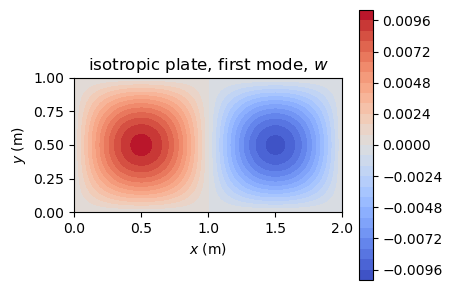

In [2]:
E, nu, h = 70e9, 0.33, 2e-3
s = Shell(model='plate_clpt_donnell', a=2., b=1., stack=[0.], plyt=h,
          laminaprop=(E, nu), m=12, n=12)
s.Nxx = -1.
eigvals, eigvecs = lb(s.calc_kC(), s.calc_kG(), silent=True)
D = E*h**3/(12*(1 - nu**2))
ms = np.arange(1, 6)
k = ((ms*s.b/s.a + s.a/(ms*s.b))**2).min()
Ncr = k*np.pi**2*D/s.b**2
print('panels: %.4f N/m, closed form: %.4f N/m (k = %.4f)'
      % (eigvals[0], Ncr, k))
iso_row = ('isotropic plate, $N_{xx,cr}$ (N/m)', eigvals[0], Ncr,
           'closed form, Timoshenko and Gere (1961)')
plot_modes([(s, eigvecs[:, 0])], ['isotropic plate, first mode, $w$'])

### Laminated plates, simply supported or with one free edge

The laminate $[0/90/-45/+45]_s$ of carbon/epoxy plies of 0.125 mm has bending-twisting coupling, $D_{16}, D_{26} \neq 0$, and no closed-form solution. The plate of $2 \times 1$ m is simply supported on all edges (SSSS) and is loaded by $N_{xx}$ or by $N_{yy}$. The plate of $1 \times 0.5$ m with the laminate $[0/90/-45/+45]$ has one free edge: $u$, $v$ and $w$ are released at $y = b$ (`y2u`, `y2v`, `y2w`) for $N_{xx}$, and at $x = a$ for $N_{yy}$. The cylindrical shell models with a large radius, $r = 10^8$ m, give the plate results.

The reference values are regression values of the panels unit test `tests/tests_shell/test_lb.py`, checked there within an absolute tolerance of 0.1 N/m.

In [3]:
LAMINA = (142.5e9, 8.7e9, 0.28, 5.1e9, 5.1e9, 5.1e9)


def ssss(model, load):
    s = Shell(model=model, a=2., b=1., r=1.e8, m=12, n=12, plyt=0.125e-3,
              stack=[0, 90, -45, +45, +45, -45, 90, 0], laminaprop=LAMINA)
    setattr(s, load, -1.)
    return s


def one_free_edge(model, load):
    s = Shell(model=model, a=1., b=0.5, r=1.e8, m=12, n=13, plyt=0.125e-3,
              stack=[0, 90, -45, +45], laminaprop=LAMINA)
    edge = 'y2' if load == 'Nxx' else 'x2'
    for field in 'uvw':
        setattr(s, edge + field, 1)
    setattr(s, load, -1.)
    return s


REF = {('SSSS', 'Nxx'): 157.5369886, ('SSSS', 'Nyy'): 58.1488566,
       ('free edge', 'Nxx'): 15.8106238, ('free edge', 'Nyy'): 13.9105}
SOURCE = 'regression value, `test_lb.py`'
rows = []
modes = {}
for model in ['plate_clpt_donnell', 'cylshell_clpt_donnell',
              'cylshell_clpt_sanders']:
    for (case, load), ref in REF.items():
        s = ssss(model, load) if case == 'SSSS' else one_free_edge(model, load)
        eigvals, eigvecs = lb(s.calc_kC(), s.calc_kG(), silent=True)
        print('%-22s %-9s %s: lambda = %.6f N/m' % (model, case, load,
                                                      eigvals[0]))
        rows.append(('`%s`, %s, %s' % (model, case, load), eigvals[0], ref,
                     SOURCE))
        if model == 'plate_clpt_donnell':
            modes[(case, load)] = (s, eigvecs[:, 0])
results_table(rows)

plate_clpt_donnell     SSSS      Nxx: lambda = 157.538625 N/m
plate_clpt_donnell     SSSS      Nyy: lambda = 58.149231 N/m


plate_clpt_donnell     free edge Nxx: lambda = 15.762885 N/m
plate_clpt_donnell     free edge Nyy: lambda = 13.910509 N/m


cylshell_clpt_donnell  SSSS      Nxx: lambda = 157.538625 N/m
cylshell_clpt_donnell  SSSS      Nyy: lambda = 58.149231 N/m


cylshell_clpt_donnell  free edge Nxx: lambda = 15.762896 N/m
cylshell_clpt_donnell  free edge Nyy: lambda = 13.910505 N/m


cylshell_clpt_sanders  SSSS      Nxx: lambda = 157.538625 N/m
cylshell_clpt_sanders  SSSS      Nyy: lambda = 58.149231 N/m


cylshell_clpt_sanders  free edge Nxx: lambda = 15.762896 N/m
cylshell_clpt_sanders  free edge Nyy: lambda = 13.910505 N/m


| quantity | panels | reference | relative difference | reference source |
|---|---|---|---|---|
| `plate_clpt_donnell`, SSSS, Nxx | 157.539 | 157.537 | +1.04e-05 | regression value, `test_lb.py` |
| `plate_clpt_donnell`, SSSS, Nyy | 58.1492 | 58.1489 | +6.44e-06 | regression value, `test_lb.py` |
| `plate_clpt_donnell`, free edge, Nxx | 15.7629 | 15.8106 | -3.02e-03 | regression value, `test_lb.py` |
| `plate_clpt_donnell`, free edge, Nyy | 13.9105 | 13.9105 | +6.59e-07 | regression value, `test_lb.py` |
| `cylshell_clpt_donnell`, SSSS, Nxx | 157.539 | 157.537 | +1.04e-05 | regression value, `test_lb.py` |
| `cylshell_clpt_donnell`, SSSS, Nyy | 58.1492 | 58.1489 | +6.44e-06 | regression value, `test_lb.py` |
| `cylshell_clpt_donnell`, free edge, Nxx | 15.7629 | 15.8106 | -3.02e-03 | regression value, `test_lb.py` |
| `cylshell_clpt_donnell`, free edge, Nyy | 13.9105 | 13.9105 | +3.49e-07 | regression value, `test_lb.py` |
| `cylshell_clpt_sanders`, SSSS, Nxx | 157.539 | 157.537 | +1.04e-05 | regression value, `test_lb.py` |
| `cylshell_clpt_sanders`, SSSS, Nyy | 58.1492 | 58.1489 | +6.44e-06 | regression value, `test_lb.py` |
| `cylshell_clpt_sanders`, free edge, Nxx | 15.7629 | 15.8106 | -3.02e-03 | regression value, `test_lb.py` |
| `cylshell_clpt_sanders`, free edge, Nyy | 13.9105 | 13.9105 | +3.49e-07 | regression value, `test_lb.py` |

The first buckling modes of the plate model. With the free edge the plate buckles with the largest deflection along the free edge.

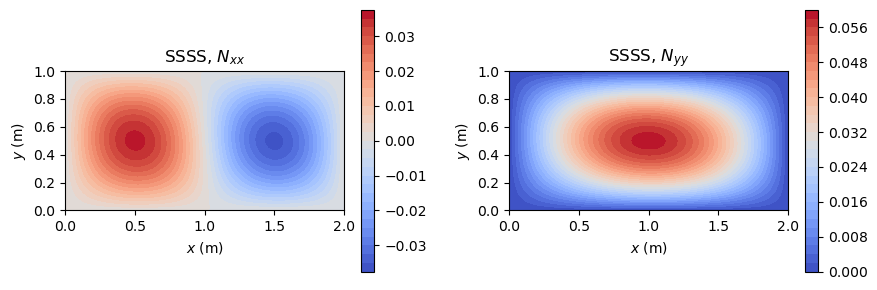

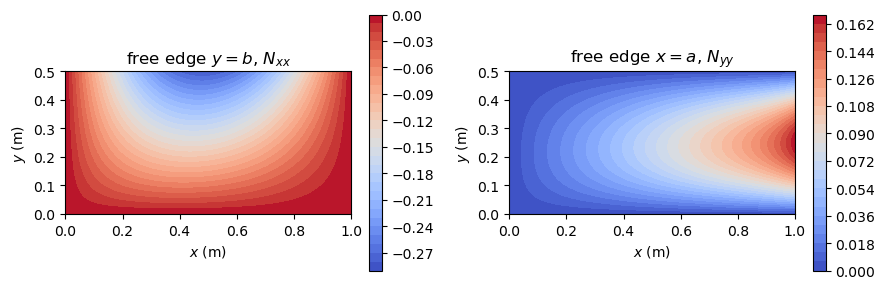

In [4]:
plot_modes([modes[('SSSS', 'Nxx')], modes[('SSSS', 'Nyy')]],
           ['SSSS, $N_{xx}$', 'SSSS, $N_{yy}$'])
plot_modes([modes[('free edge', 'Nxx')], modes[('free edge', 'Nyy')]],
           ['free edge $y = b$, $N_{xx}$', 'free edge $x = a$, $N_{yy}$'])

### Combined loads on a curved panel

Combined load cases are given by more than one stress resultant, here compression and shear, $N_{xx} = N_{xy} = -1$ N/m, on an isotropic aluminium cylindrical panel of radius $r = 2$ m with Donnell's kinematics, simply supported. The load multiplier scales both resultants. No reference value is available for this case.

first load multipliers: [4651.652 4699.137 5531.811 5587.955]


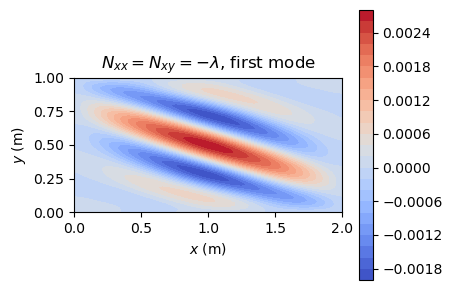

In [5]:
s = Shell(model='cylshell_clpt_donnell', a=2., b=1., r=2., m=12, n=12,
          stack=[0.], plyt=1e-3, laminaprop=(70e9, 0.33))
s.Nxx = -1.
s.Nxy = -1.
eigvals, eigvecs = lb(s.calc_kC(), s.calc_kG(), silent=True)
print('first load multipliers:', np.round(eigvals[:4], 3))
plot_modes([(s, eigvecs[:, 0])], ['$N_{xx} = N_{xy} = -\\lambda$, first mode'])

## Pre-buckling stress state from a static analysis

$\boldsymbol{K}_G$ can also be computed from the Ritz constants $\boldsymbol{c}_0$ of a linear static solution, `Shell.calc_kG(c=c0)`, which integrates the pre-buckling stress field numerically. The stresses then follow the boundary conditions instead of being assumed constant.

The laminated plate of $8 \times 4$ m, $[0/90/90/0/-45/+45]$, is compressed by a load distributed along $x = a$. The in-plane boundary conditions let the edges move: $u$ is free except at $x = 0$, and $v$ is constrained only along $x = 0$. The critical $N_{xx}$ is computed first with a constant $N_{xx} = -1$ and then with the pre-buckling state of the static solution under the same load. The reference values are regression values of the panels unit test `tests/tests_shell/test_lb_num.py`, checked there within 0.01 N/m.

In [6]:
def plate_8x4(model):
    p = Shell(model=model, a=8., b=4., r=1.e8, m=8, n=9, plyt=0.125e-3,
              stack=[0, 90, 90, 0, -45, +45], laminaprop=LAMINA)
    p.x1ur = 1
    p.x2u = p.x2ur = 1
    p.y1u = p.y1ur = p.y2u = p.y2ur = 1
    p.x1v = p.x1vr = 0
    p.x2v = p.x2vr = p.y1v = p.y1vr = p.y2v = p.y2vr = 1
    return p


import warnings
warnings.showwarning = lambda message, category, *args, **kwargs: print(
    '%s: %s' % (category.__name__, message))
rows = []
for model in ['plate_clpt_donnell', 'cylshell_clpt_donnell',
              'cylshell_clpt_sanders', 'plate_fsdt_donnell',
              'plate_tsdt_donnell']:
    p = plate_8x4(model)
    p.Nxx = -1.
    k0 = p.calc_kC(silent=True)
    eig_cte, _ = lb(k0, p.calc_kG(silent=True), silent=True)
    p.Nxx = 0.
    p.add_distr_load_fixed_x(p.a, lambda y: -1., None, None)
    c0 = solve(k0, p.calc_fext(silent=True), silent=True)
    eig_static, modes = lb(k0, p.calc_kG(c=c0, silent=True), silent=True)
    print('%-22s constant Nxx: %.5f, from the static solution: %.5f'
          % (model, eig_cte[0], eig_static[0]))
    rows.append(('`%s`, constant $N_{xx}$' % model, eig_cte[0], 4.47698,
                 'regression value, `test_lb_num.py`'))
    rows.append(('`%s`, $N_{xx}$ from static' % model, eig_static[0], 4.39212,
                 'regression value, `test_lb_num.py`'))
results_table(rows)

plate_clpt_donnell     constant Nxx: 4.47698, from the static solution: 4.39212
cylshell_clpt_donnell  constant Nxx: 4.47695, from the static solution: 4.39209
cylshell_clpt_sanders  constant Nxx: 4.47695, from the static solution: 4.39209


plate_fsdt_donnell     constant Nxx: 4.47697, from the static solution: 4.39212


plate_tsdt_donnell     constant Nxx: 4.47697, from the static solution: 4.39212


| quantity | panels | reference | relative difference | reference source |
|---|---|---|---|---|
| `plate_clpt_donnell`, constant $N_{xx}$ | 4.47698 | 4.47698 | -7.59e-07 | regression value, `test_lb_num.py` |
| `plate_clpt_donnell`, $N_{xx}$ from static | 4.39212 | 4.39212 | -1.05e-07 | regression value, `test_lb_num.py` |
| `cylshell_clpt_donnell`, constant $N_{xx}$ | 4.47695 | 4.47698 | -6.94e-06 | regression value, `test_lb_num.py` |
| `cylshell_clpt_donnell`, $N_{xx}$ from static | 4.39209 | 4.39212 | -6.01e-06 | regression value, `test_lb_num.py` |
| `cylshell_clpt_sanders`, constant $N_{xx}$ | 4.47695 | 4.47698 | -6.94e-06 | regression value, `test_lb_num.py` |
| `cylshell_clpt_sanders`, $N_{xx}$ from static | 4.39209 | 4.39212 | -6.01e-06 | regression value, `test_lb_num.py` |
| `plate_fsdt_donnell`, constant $N_{xx}$ | 4.47697 | 4.47698 | -1.62e-06 | regression value, `test_lb_num.py` |
| `plate_fsdt_donnell`, $N_{xx}$ from static | 4.39212 | 4.39212 | -9.70e-07 | regression value, `test_lb_num.py` |
| `plate_tsdt_donnell`, constant $N_{xx}$ | 4.47697 | 4.47698 | -1.50e-06 | regression value, `test_lb_num.py` |
| `plate_tsdt_donnell`, $N_{xx}$ from static | 4.39212 | 4.39212 | -8.44e-07 | regression value, `test_lb_num.py` |

For some models, `structsolve.lb` warns that its sparse eigensolvers did not reach the required accuracy, and solves the problem with its dense solver instead; the results are not affected.

The pre-buckling stress resultant $N_{xx}$ of the static solution, and the first buckling mode computed with it, for the last model of the loop:

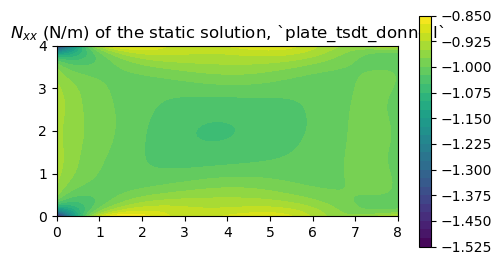

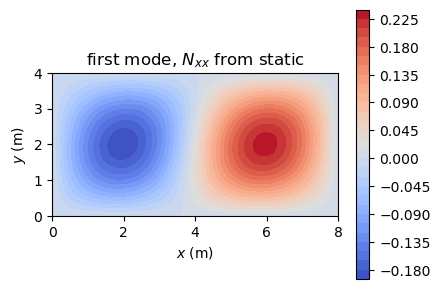

In [7]:
mesh, fields = p.stress(c0, gridx=101, gridy=61)
fig, ax = plt.subplots(figsize=(5.5, 3))
cf = ax.contourf(mesh['Xs'], mesh['Ys'], fields['Nxx'], levels=30,
                 cmap='viridis')
fig.colorbar(cf, ax=ax)
ax.set_title('$N_{xx}$ (N/m) of the static solution, `%s`' % p.model)
ax.set_aspect('equal')
plt.show()
plot_modes([(p, modes[:, 0])], ['first mode, $N_{xx}$ from static'])

The isotropic plate agrees with the closed form. The regression values document the results of the laminated cases.

## References

1. S. P. Timoshenko and J. M. Gere, "Theory of Elastic Stability". 2nd ed., McGraw-Hill, New York, 1961.
2. S. G. P. Castro and M. V. Donadon, "Assembly of semi-analytical models to address linear buckling and vibration of stiffened composite panels with debonding defect". Composite Structures, 160:232-247, 2017. https://doi.org/10.1016/j.compstruct.2016.10.026.